In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import sys

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import warnings
warnings.filterwarnings('ignore')

%matplotlib inline

In [4]:
# Import feature engineering function
sys.path.append('../src')

from feature_engineering import create_customer_features

In [5]:
# Load the cleaned dataset
df = pd.read_csv('../data/bank_transaction_cleaned.csv')

print("Original dataset shape:", df.shape)

df.head()

Original dataset shape: (987516, 9)


,TransactionID,CustomerID,CustomerDOB,CustGender,CustLocation,CustAccountBalance,TransactionDate,TransactionTime,TransactionAmount (INR)
0,T1,C5841053,1994-01-10,F,JAMSHEDPUR,17819.05,2016-08-02,14:32:07,25.0
1,T2,C2142763,1957-04-04,M,JHAJJAR,2270.69,2016-08-02,14:18:58,27999.0
2,T3,C4417068,1996-11-26,F,MUMBAI,17874.44,2016-08-02,14:27:12,459.0
3,T4,C5342380,1973-09-14,F,MUMBAI,866503.21,2016-08-02,14:27:14,2060.0
4,T5,C9031234,1988-03-24,F,NAVI MUMBAI,6714.43,2016-08-02,18:11:56,1762.5


In [6]:
# Call the function created in feature_engineering.py to generate customer-level features
customer_features = create_customer_features(df)

print("Customer-level dataset shape:", customer_features.shape)

customer_features.head()


Customer-level dataset shape: (840651, 9)


,CustomerID,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,C1010011,28.5,2553.0,2553.0,2,3107.027197,5106.0,76340.635,2
1,C1010012,22.0,1499.0,1499.0,1,0.000000,1499.0,24204.490,1
2,C1010014,28.0,727.5,727.5,2,675.286976,1455.0,100112.950,2
3,C1010018,26.0,30.0,30.0,1,0.000000,30.0,496.180,1
4,C1010024,51.0,5000.0,5000.0,1,0.000000,5000.0,87058.650,1


In [7]:
customer_features.columns

Index(['CustomerID', 'CustomerAge', 'AvgTransactionAmount',
       'MedianTransactionAmount', 'TransactionFrequency', 'TransactionStd',
       'TotalTransactionAmount', 'AccountBalance', 'ActiveDays'],
      dtype='object')

In [8]:
# Inspect the features
print("Number of customers:", customer_features.shape[0])
print("Number of columns:", customer_features.shape[1])

Number of customers: 840651
Number of columns: 9


In [9]:
customer_features.isnull().sum()

CustomerID                    0
CustomerAge                1424
AvgTransactionAmount          0
MedianTransactionAmount       0
TransactionFrequency          0
TransactionStd                0
TotalTransactionAmount        0
AccountBalance                0
ActiveDays                    0
dtype: int64

- null values in customerAge shows implausible ages (<18 and >100)

In [10]:
customer_features.dropna(inplace = True )

In [11]:
customer_features[customer_features['CustomerAge'].isna()]

,CustomerID,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays


In [12]:
customer_features.describe()

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
count,839227.000000,8.392270e+05,8.392270e+05,839227.000000,839227.000000,8.392270e+05,8.392270e+05,839227.000000
mean,30.842815,1.453970e+03,1.439764e+03,1.174997,239.476636,1.707454e+03,1.043642e+05,1.171082
std,8.349556,6.047975e+03,6.032823e+03,0.436022,2126.338991,6.697869e+03,7.842569e+05,0.429704
min,18.000000,0.000000e+00,0.000000e+00,1.000000,0.000000,0.000000e+00,0.000000e+00,1.000000
25%,25.000000,1.800000e+02,1.780000e+02,1.000000,0.000000,1.980000e+02,5.259380e+03,1.000000
50%,29.000000,4.750000e+02,4.650000e+02,1.000000,0.000000,5.000000e+02,1.730383e+04,1.000000
75%,34.000000,1.176000e+03,1.155000e+03,1.000000,0.000000,1.420000e+03,5.601785e+04,1.000000
max,86.000000,1.560035e+06,1.560035e+06,6.000000,511784.089233,1.560035e+06,1.150355e+08,6.000000


In [13]:
print(
    "Duplicate CustomerIDs:",
    customer_features['CustomerID'].duplicated().sum()
)

Duplicate CustomerIDs: 0


In [14]:
# Select features
features = [
    'CustomerAge',
    'AvgTransactionAmount',
    'MedianTransactionAmount',
    'TransactionFrequency',
    'TransactionStd',
    'TotalTransactionAmount',
    'AccountBalance',
    'ActiveDays'
]

X = customer_features[features].copy()

X.head()

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,28.5,2553.0,2553.0,2,3107.027197,5106.0,76340.635,2
1,22.0,1499.0,1499.0,1,0.000000,1499.0,24204.490,1
2,28.0,727.5,727.5,2,675.286976,1455.0,100112.950,2
3,26.0,30.0,30.0,1,0.000000,30.0,496.180,1
4,51.0,5000.0,5000.0,1,0.000000,5000.0,87058.650,1


In [15]:
X = X.replace([np.inf, -np.inf], np.nan)

print("Missing values:")
print(X.isnull().sum())

Missing values:
CustomerAge                0
AvgTransactionAmount       0
MedianTransactionAmount    0
TransactionFrequency       0
TransactionStd             0
TotalTransactionAmount     0
AccountBalance             0
ActiveDays                 0
dtype: int64


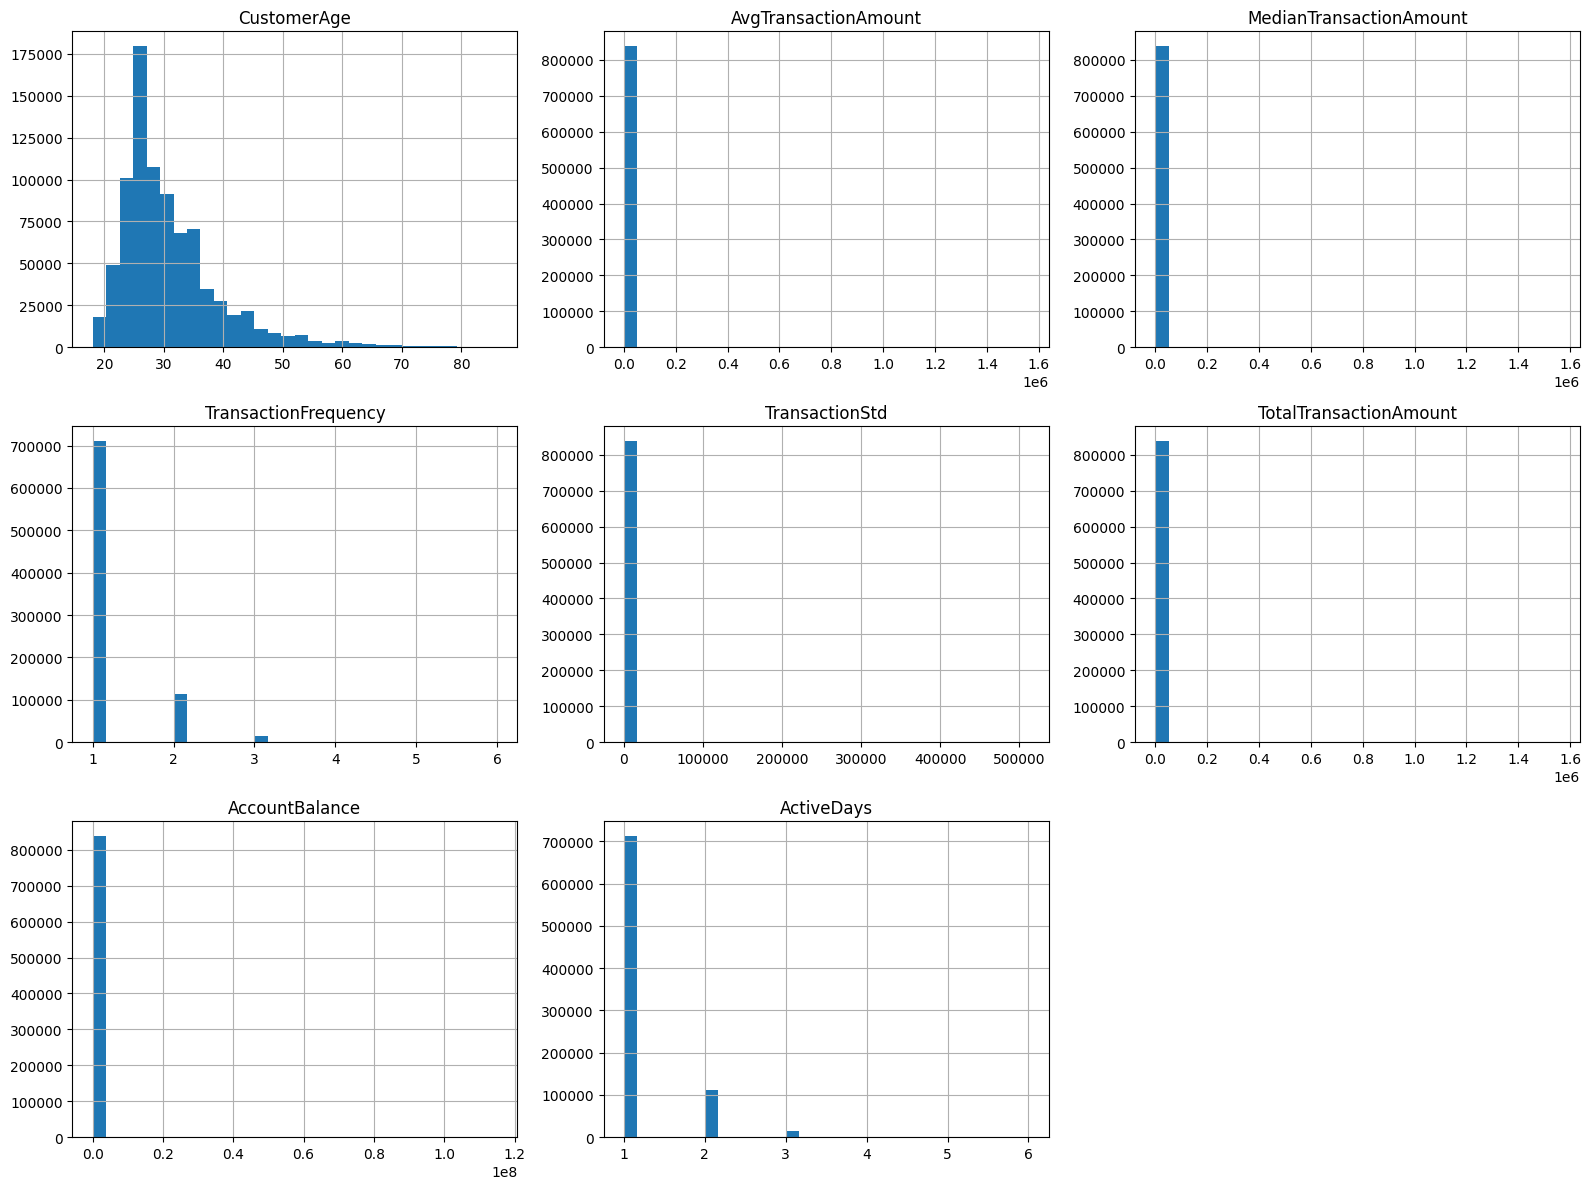

In [16]:
# Examine feature distribution
X.hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.show()

In [17]:
# Scale the features
from sklearn.preprocessing import StandardScaler, RobustScaler

scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X),
    columns=features,
    index=X.index
)

X_scaled.head()

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,-0.280592,0.181719,0.184530,1.892115,1.348587,0.507407,-0.035733,1.929043
1,-1.059077,0.007446,0.009819,-0.401349,-0.112624,-0.031123,-0.102211,-0.398140
2,-0.340475,-0.120118,-0.118065,1.892115,0.204958,-0.037692,-0.005421,1.929043
3,-0.580009,-0.235446,-0.233682,-0.401349,-0.112624,-0.250446,-0.132441,-0.398140
4,2.414164,0.586317,0.590145,-0.401349,-0.112624,0.491581,-0.022066,-0.398140


In [18]:
X_scaled.shape

(839227, 8)

Running standard DBSCAN directly on 839,227 customers may be computationally expensive. It can consume substantial memory and time, especially with eight dimensions.

In [19]:
print(X.describe())

         CustomerAge  AvgTransactionAmount  MedianTransactionAmount  \
count  839227.000000          8.392270e+05             8.392270e+05   
mean       30.842815          1.453970e+03             1.439764e+03   
std         8.349556          6.047975e+03             6.032823e+03   
min        18.000000          0.000000e+00             0.000000e+00   
25%        25.000000          1.800000e+02             1.780000e+02   
50%        29.000000          4.750000e+02             4.650000e+02   
75%        34.000000          1.176000e+03             1.155000e+03   
max        86.000000          1.560035e+06             1.560035e+06   

       TransactionFrequency  TransactionStd  TotalTransactionAmount  \
count         839227.000000   839227.000000            8.392270e+05   
mean               1.174997      239.476636            1.707454e+03   
std                0.436022     2126.338991            6.697869e+03   
min                1.000000        0.000000            0.000000e+00   
25%  

In [20]:
skewness = X.skew().sort_values(ascending=False)

print(skewness)

AccountBalance             69.169224
MedianTransactionAmount    64.338254
AvgTransactionAmount       63.903843
TotalTransactionAmount     51.969058
TransactionStd             49.456292
ActiveDays                  2.664201
TransactionFrequency        2.658079
CustomerAge                 1.769883
dtype: float64


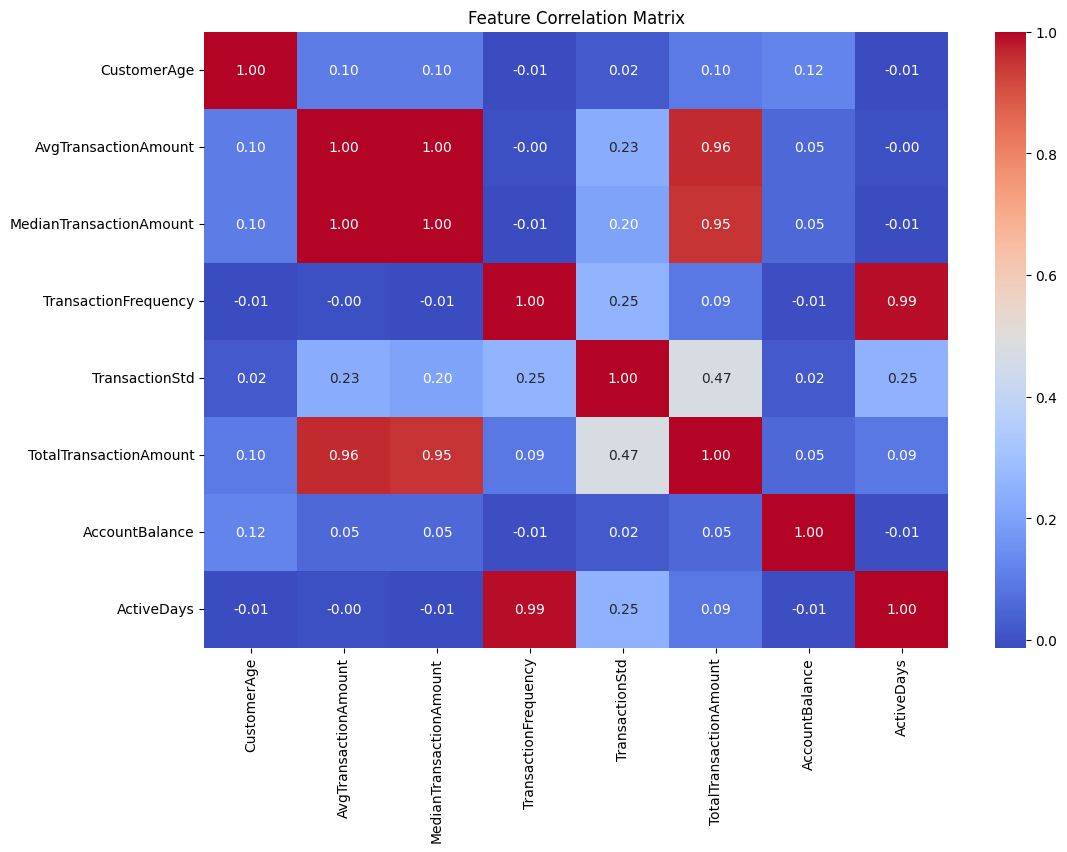

In [21]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    X.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Matrix")
plt.show()

- Customer features are extremely right-skewed
- Most customers have only one transaction
- Financial features contain extreme values

##### Applying logarithmic transformation

In [22]:
# Create a copy so that the original features remain unchanged
X_transformed = X.copy()

# Features suitable for logarithmic transformation
log_features = [
    'AvgTransactionAmount',
    'MedianTransactionAmount',
    'TransactionStd',
    'TotalTransactionAmount',
    'AccountBalance'
]

# Check that all selected values are non-negative
print((X_transformed[log_features] < 0).sum())

# Apply log1p transformation
X_transformed[log_features] = np.log1p(
    X_transformed[log_features]
)

X_transformed.head()

AvgTransactionAmount       0
MedianTransactionAmount    0
TransactionStd             0
TotalTransactionAmount     0
AccountBalance             0
dtype: int64


,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
0,28.5,7.845416,7.845416,2,8.041743,8.538367,11.242974,2
1,22.0,7.313220,7.313220,1,0.000000,7.313220,10.094335,1
2,28.0,6.590988,6.590988,2,6.516618,7.283448,11.514064,2
3,26.0,3.433987,3.433987,1,0.000000,3.433987,6.208952,1
4,51.0,8.517393,8.517393,1,0.000000,8.517393,11.374349,1


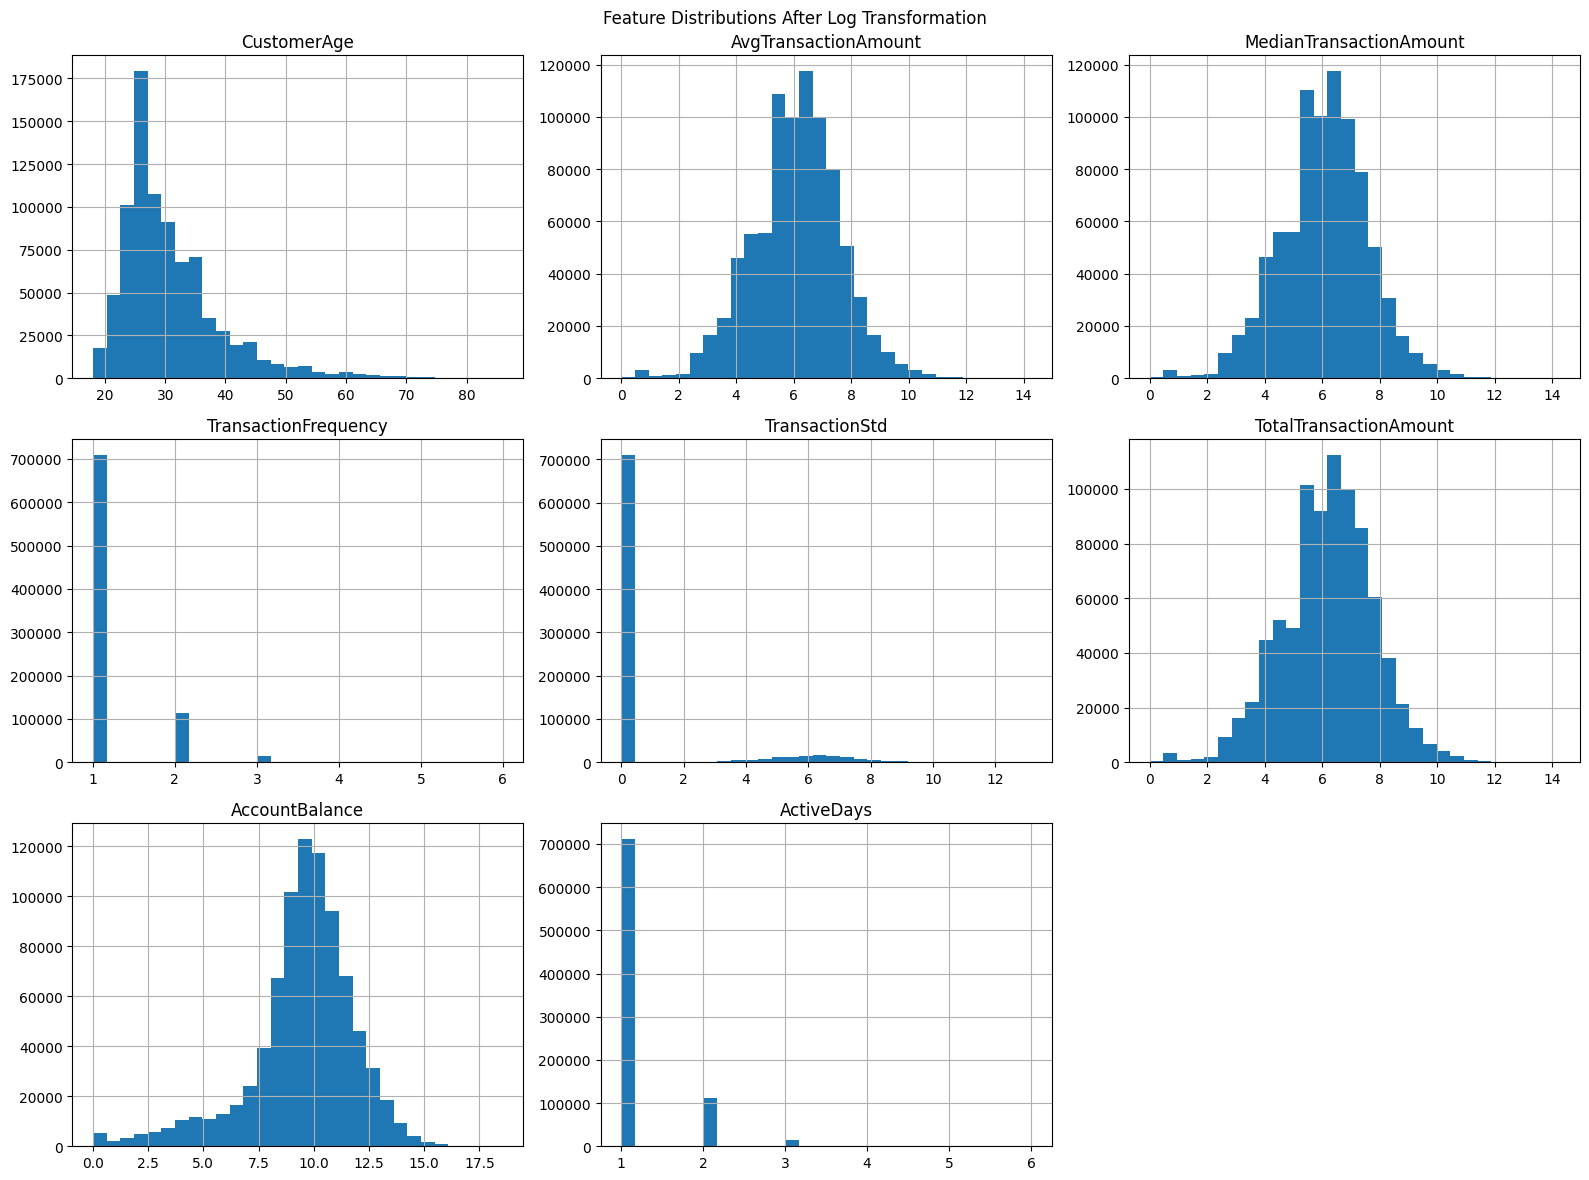

In [23]:
X_transformed.hist(
    figsize=(16, 12),
    bins=30
)

plt.suptitle("Feature Distributions After Log Transformation")
plt.tight_layout()
plt.show()

In [24]:
# Skewness after transformation
print(
    X_transformed.skew().sort_values(ascending=False)
)

ActiveDays                 2.664201
TransactionFrequency       2.658079
TransactionStd             2.211205
CustomerAge                1.769883
MedianTransactionAmount   -0.177522
AvgTransactionAmount      -0.184732
TotalTransactionAmount    -0.204903
AccountBalance            -1.078602
dtype: float64


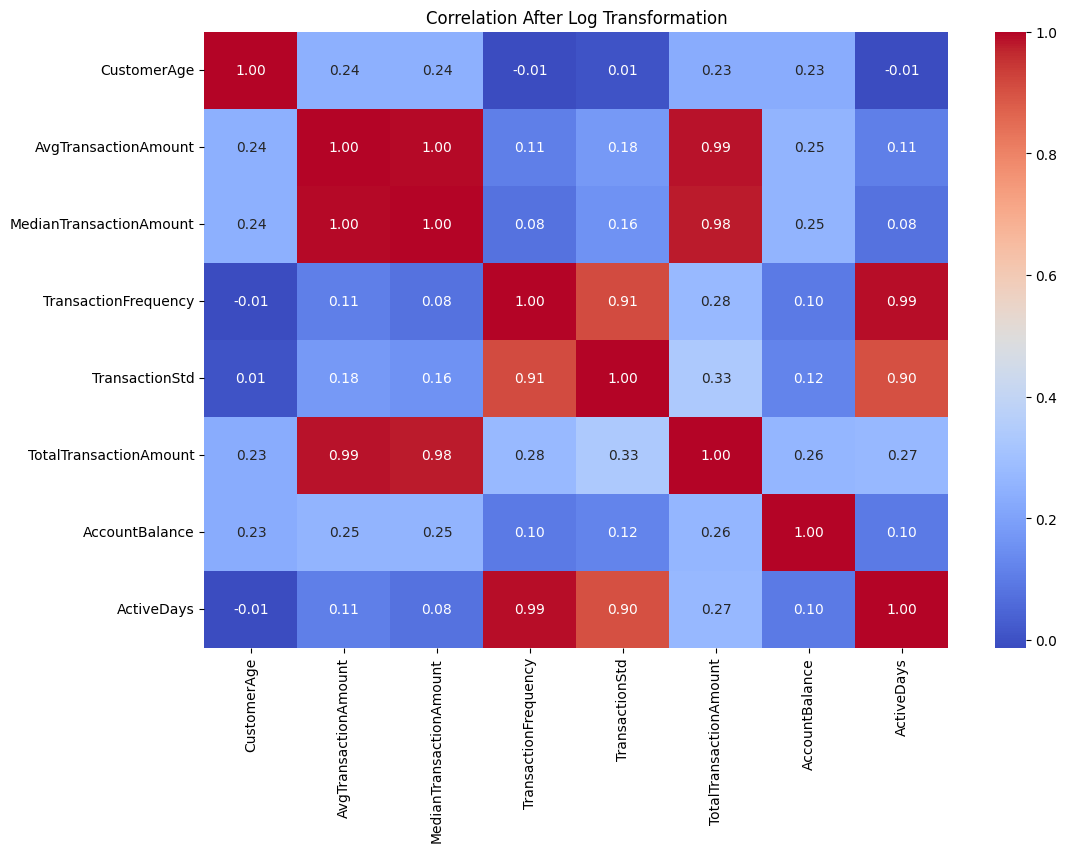

In [25]:
# Correlation after transformation
plt.figure(figsize=(12, 8))

sns.heatmap(
    X_transformed.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation After Log Transformation")
plt.show()

- Skewnwss has been reduced
- but correlation shows several features are highly redundant
- Average and median transaction amounts are almost identical in their relationship with other features.



- Total transaction amount is strongly related to average transaction amount.



- TransactionFrequency and ActiveDays are almost interchangeable in this dataset.



- TransactionStd is strongly related to frequency, partly because customers with only one transaction have a standard deviation of zero.

##### Exeperiment - keeping only few features of the ones that are highly correlated

In [26]:
selected_features = [
    'CustomerAge',
    'AvgTransactionAmount',
    'TransactionFrequency',
    'TransactionStd',
    'AccountBalance'
]

X_selected = X_transformed[selected_features].copy()

print("Selected dataset shape:", X_selected.shape)
X_selected.head()

Selected dataset shape: (839227, 5)


,CustomerAge,AvgTransactionAmount,TransactionFrequency,TransactionStd,AccountBalance
0,28.5,7.845416,2,8.041743,11.242974
1,22.0,7.313220,1,0.000000,10.094335
2,28.0,6.590988,2,6.516618,11.514064
3,26.0,3.433987,1,0.000000,6.208952
4,51.0,8.517393,1,0.000000,11.374349


In [27]:
# Scalling these features
scaler = StandardScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_selected),
    columns=X_selected.columns,
    index=X_selected.index
)

X_scaled.describe()

,CustomerAge,AvgTransactionAmount,TransactionFrequency,TransactionStd,AccountBalance
count,8.392270e+05,8.392270e+05,8.392270e+05,8.392270e+05,8.392270e+05
mean,-1.972853e-16,-1.626102e-16,-4.158810e-17,1.472517e-16,-1.532799e-16
std,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00,1.000001e+00
min,-1.538144e+00,-3.948282e+00,-4.013487e-01,-4.093172e-01,-3.937952e+00
25%,-6.997759e-01,-5.713003e-01,-4.013487e-01,-4.093172e-01,-3.827372e-01
50%,-2.207083e-01,5.681849e-02,-4.013487e-01,-4.093172e-01,1.113697e-01
75%,3.781263e-01,6.449120e-01,-4.013487e-01,-4.093172e-01,5.988044e-01
max,6.606006e+00,5.315261e+00,1.106597e+01,5.352986e+00,3.763703e+00


In [28]:
# Preparing a sample for DBSCAN
X_sample = X_scaled.sample(
    n=20000,
    random_state=42
)

print("Sample shape:", X_sample.shape)

Sample shape: (20000, 5)


In [29]:
# Generate the k-distance graph
from sklearn.neighbors import NearestNeighbors

neighbors = NearestNeighbors(
    n_neighbors=5,
    metric='euclidean'
)

neighbors.fit(X_sample)

distances, indices = neighbors.kneighbors(X_sample)

k_distances = np.sort(distances[:, -1])

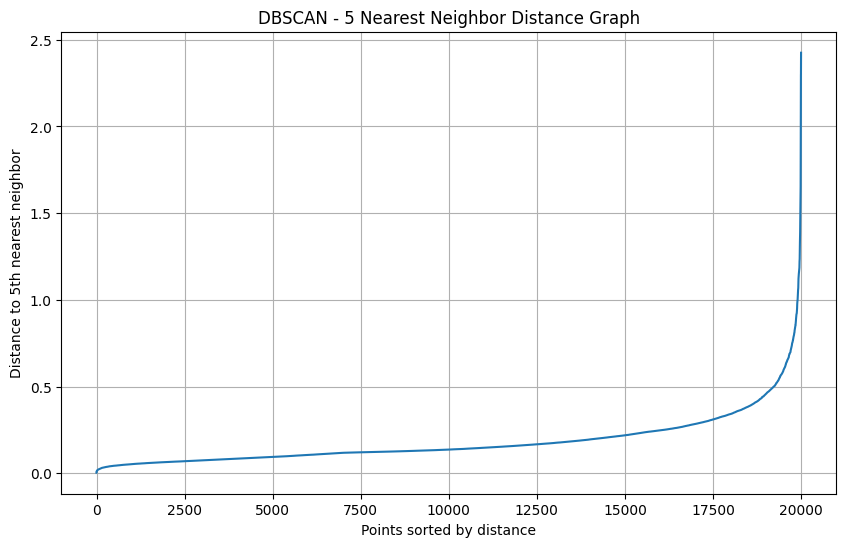

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(k_distances)

plt.xlabel("Points sorted by distance")
plt.ylabel("Distance to 5th nearest neighbor")
plt.title("DBSCAN - 5 Nearest Neighbor Distance Graph")

plt.grid(True)
plt.show()

try esp values between 0.4 and 0.7

In [31]:
from sklearn.cluster import DBSCAN
import pandas as pd

eps_values = [0.4, 0.5, 0.6]
min_samples_values = [5, 10, 15]

results = []

for eps in eps_values:
    for min_samples in min_samples_values:

        dbscan = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean',
            n_jobs=-1
        )

        labels = dbscan.fit_predict(X_sample)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = (labels == -1).sum()
        noise_percentage = (n_noise / len(labels)) * 100

        results.append({
            'eps': eps,
            'min_samples': min_samples,
            'clusters': n_clusters,
            'noise_points': n_noise,
            'noise_percentage': round(noise_percentage, 2)
        })

results_df = pd.DataFrame(results)

results_df

,eps,min_samples,clusters,noise_points,noise_percentage
0,0.4,5,15,851,4.26
1,0.4,10,5,1517,7.58
2,0.4,15,5,2039,10.20
3,0.5,5,12,472,2.36
4,0.5,10,3,803,4.01
5,0.5,15,4,1075,5.38
6,0.6,5,7,279,1.40
7,0.6,10,3,479,2.40
8,0.6,15,3,608,3.04


(0.6, 5) — seven clusters, lowest noise.

(0.5, 5) — twelve clusters.



(0.4, 5) — fifteen clusters.



(0.5, 10) — three clusters.



(0.6, 10) — three clusters.

In [32]:
# Examine cluster size
configs = [
    (0.6, 5),
    (0.5, 5),
    (0.4, 5),
    (0.5, 10),
    (0.6, 10)
]

cluster_results = {}

for eps, min_samples in configs:

    dbscan = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric='euclidean',
        n_jobs=-1
    )

    labels = dbscan.fit_predict(X_sample)

    cluster_results[(eps, min_samples)] = labels

    cluster_counts = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )

    print(f"\nConfiguration: eps={eps}, min_samples={min_samples}")
    print(cluster_counts)


Configuration: eps=0.6, min_samples=5
-1      279
 0    16752
 1     2612
 2      309
 3       16
 4       18
 5        9
 6        5
Name: count, dtype: int64

Configuration: eps=0.5, min_samples=5
-1       472
 0     16655
 1      2550
 2       268
 3         5
 4        10
 5         3
 6        10
 7         5
 8         7
 9         7
 10        3
 11        5
Name: count, dtype: int64

Configuration: eps=0.4, min_samples=5
-1       851
 0     16477
 1      2374
 2       229
 3         8
 4        12
 5         7
 6         5
 7         5
 8         5
 9         5
 10        5
 11        5
 12        4
 13        3
 14        5
Name: count, dtype: int64

Configuration: eps=0.5, min_samples=10
-1      803
 0    16503
 1     2449
 2      245
Name: count, dtype: int64

Configuration: eps=0.6, min_samples=10
-1      479
 0    16664
 1     2578
 2      279
Name: count, dtype: int64


- DBSCAN is consistently finding two dominant customer groups, with a much smaller third group.
- Investigating three configurations
- (0.5, 10) Simple three-cluster solution	
- (0.6, 10)	Three clusters with lower noise
- (0.6, 5)	Tests whether the additional small clusters are meaningful

##### Cluster profiling


In [33]:
# understand what differentiates the customers in each cluster.
selected_features = [
    'CustomerAge',
    'AvgTransactionAmount',
    'TransactionFrequency',
    'TransactionStd',
    'AccountBalance'
]

for config in [(0.5, 10), (0.6, 10), (0.6, 5)]:

    labels = cluster_results[config]

    profile_data = X.loc[
        X_sample.index, selected_features
    ].copy()

    profile_data['Cluster'] = labels

    print(f"\nConfiguration: {config}")

    # Cluster sizes
    print("\nCluster sizes:")
    print(
        profile_data['Cluster']
        .value_counts()
        .sort_index()
    )

    # Median feature values
    print("\nCluster median profiles:")
    print(
        profile_data
        .groupby('Cluster')[selected_features]
        .median()
        .round(2)
    )


Configuration: (0.5, 10)

Cluster sizes:
Cluster
-1      803
 0    16503
 1     2449
 2      245
Name: count, dtype: int64

Cluster median profiles:
         CustomerAge  AvgTransactionAmount  TransactionFrequency  \
Cluster                                                            
-1              40.0                512.00                   1.0   
 0              29.0                447.00                   1.0   
 1              29.5                611.50                   2.0   
 2              28.0                692.82                   3.0   

         TransactionStd  AccountBalance  
Cluster                                  
-1                 0.00        14126.50  
 0                 0.00        16370.70  
 1               485.41        25798.73  
 2               650.79        15280.26  

Configuration: (0.6, 10)

Cluster sizes:
Cluster
-1      479
 0    16664
 1     2578
 2      279
Name: count, dtype: int64

Cluster median profiles:
         CustomerAge  AvgTransactionAmo

- DBSCAN is primarily separating customers according to their transaction frequency, with transaction amount and account balance providing additional differentiation.
- Current preference is (0.6,10)
- It produces three reasonably interpretable clusters.
- It reduces noise from 4.01% to 2.40%.
- It avoids the tiny clusters produced by (0.6, 5).

##### Evaluate clustering quality

Silhouette Score: Measures how well-separated the clusters are.



Davies-Bouldin Index: Measures similarity between clusters; lower is generally better.



Calinski-Harabasz Index: Measures between-cluster dispersion relative to within-cluster dispersion; higher is generally better.

In [34]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

import numpy as np
import pandas as pd

evaluation_results = []

for config in [(0.5, 10), (0.6, 10), (0.6, 5)]:

    labels = cluster_results[config]

    # Exclude noise
    mask = labels != -1

    X_clustered = X_sample.loc[mask]
    labels_clustered = labels[mask]

    # Sample for computational efficiency
    rng = np.random.RandomState(42)

    sample_indices = rng.choice(
        len(X_clustered),
        size=min(3000, len(X_clustered)),
        replace=False
    )

    X_eval = X_clustered.iloc[sample_indices]
    y_eval = labels_clustered[sample_indices]

    # Calculate evaluation metrics
    silhouette = silhouette_score(
        X_eval, y_eval, metric='euclidean'
    )

    db_index = davies_bouldin_score(
        X_eval, y_eval
    )

    ch_score = calinski_harabasz_score(
        X_eval, y_eval
    )

    evaluation_results.append({
        'eps': config[0],
        'min_samples': config[1],
        'Silhouette Score': silhouette,
        'Davies-Bouldin Index': db_index,
        'Calinski-Harabasz Index': ch_score
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df.round(4)

,eps,min_samples,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,0.5,10,0.4843,0.8138,1013.2704
1,0.6,10,0.4713,0.8875,977.5060
2,0.6,5,0.2366,0.7258,385.8012


Configuration 1: (0.5, 10)
Best overall candidate
- Highest Silhouette Score.
- Lowest Davies-Bouldin Index.
- Highest Calinski-Harabasz Index.
- Three reasonably interpretable clusters.
All three metrics favor this configuration.

#### Visualize clusters using PCA

In [35]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_sample)

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

print(
    "Total explained variance:",
    pca.explained_variance_ratio_.sum()
)

Explained variance: [0.40031069 0.28473459]
Total explained variance: 0.6850452828580504


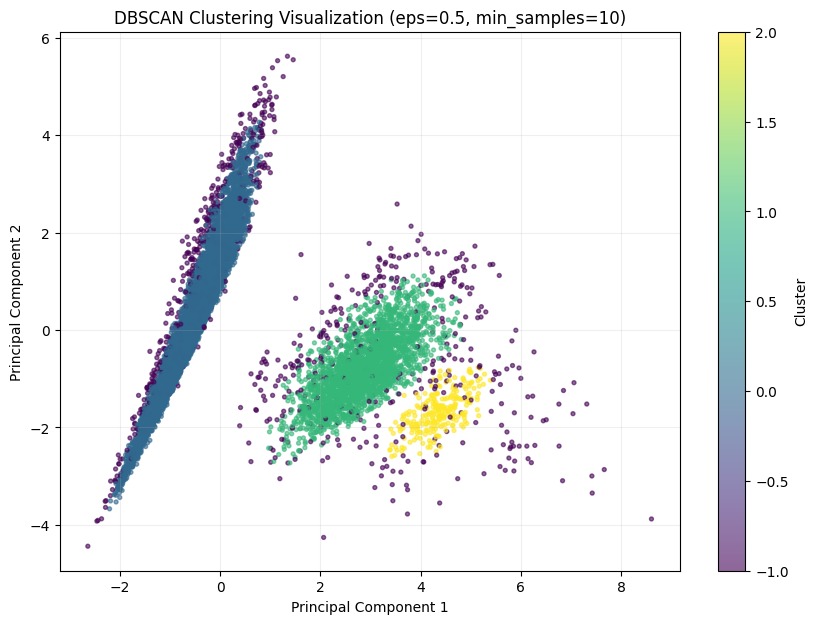

In [36]:
best_labels = cluster_results[(0.5, 10)]

plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=best_labels,
    cmap='viridis',
    s=8,
    alpha=0.6
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('DBSCAN Clustering Visualization (eps=0.5, min_samples=10)')

plt.colorbar(scatter, label='Cluster')
plt.grid(alpha=0.2)
plt.show()

- Clusters have visible structure
- Cluster 0 is elongated means DBSCAN can identify arbitrarily shaped clusters
- Noise points are distrubuted around the clusters

In [37]:
# Check the explained variance
explained_variance = pca.explained_variance_ratio_

print("PC1:", explained_variance[0])
print("PC2:", explained_variance[1])

print(
    "Total explained variance:",
    explained_variance.sum() * 100,
    "%"
)

PC1: 0.40031069083396675
PC2: 0.28473459202408363
Total explained variance: 68.50452828580504 %


In [38]:
# Comapre cluster characteristics using cluster means
best_labels = cluster_results[(0.5, 10)]

profile_data = X.loc[
    X_sample.index,
    selected_features
].copy()

profile_data['Cluster'] = best_labels

cluster_means = (
    profile_data
    .groupby('Cluster')[selected_features]
    .mean()
    .round(2)
)

cluster_means

,CustomerAge,AvgTransactionAmount,TransactionFrequency,TransactionStd,AccountBalance
Cluster,,,,,
-1,43.51,6076.78,1.71,1799.94,763448.58
0,30.44,1272.28,1.00,0.00,84109.21
1,30.34,1208.71,2.00,1228.38,75046.72
2,28.53,929.44,3.00,958.42,23681.93


- The PCA projection retains 68.50% of the total variance.
- DBSCAN has identified three customer groups with different transaction behaviours.
- The noise group contains customers with unusually high average transaction amounts and account balances.

#### Investigating the noise customer

In [39]:
# Compare mean and median profiles of noise customers and clustered customers
best_labels = cluster_results[(0.5, 10)]

profile_data = X.loc[
    X_sample.index,
    selected_features
].copy()

profile_data['Cluster'] = best_labels

noise_comparison = (
    profile_data
    .groupby('Cluster')[selected_features]
    .agg(['mean', 'median', 'std'])
    .round(2)
)

noise_comparison

CustomerAge               AvgTransactionAmount                    \
               mean median    std                 mean  median       std   
Cluster                                                                    
-1            43.51   40.0  16.08              6076.78  512.00  17295.30   
 0            30.44   29.0   7.87              1272.28  447.00   3458.81   
 1            30.34   29.5   5.37              1208.71  611.50   1990.54   
 2            28.53   28.0   3.21               929.44  692.82    750.09   

        TransactionFrequency              TransactionStd                   \
                        mean median   std           mean  median      std   
Cluster                                                                     
-1                      1.71    1.0  0.87        1799.94    0.00  7474.25   
 0                      1.00    1.0  0.00           0.00    0.00     0.00   
 1                      2.00    2.0  0.00        1228.38  485.41  2595.92   
 2                      3.00    3.0  0.00         958.42  650.79   932.50   

        AccountBalance                        
                  mean    median         std  
Cluster                                       
-1           763448.58  14126.50  4734538.07  
 0            84109.21  16370.70   285096.45  
 1            75046.72  25798.73   164656.23  
 2            23681.93  15280.26    22770.14

In [40]:
# Checking the distribution of account balance in the noise group
noise_data = profile_data[
    profile_data['Cluster'] == -1
]

noise_data['AccountBalance'].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    8.030000e+02
mean     7.634486e+05
std      4.734538e+06
min      0.000000e+00
25%      5.831100e+02
50%      1.412649e+04
75%      1.911221e+05
90%      1.121946e+06
95%      3.047968e+06
99%      1.540079e+07
max      1.150355e+08
Name: AccountBalance, dtype: float64

- Mean(7.63 lakh) is more than 54 times the median(14,126), account balance distribution is extremely right-skewed 
- Higher median customer age.



- Greater variation in transaction frequency.



- Much greater variation in transaction amounts.



- Extremely high variation in account balances.

#### Validating the selected DBSCAN model on a larger dataset and assessing its scalability.

- Current configurations : esp=0.5, min_samples=10, clusters=3, noise percentage=4.01% and Silhouette score=0.4843
- We initially trained DBSCAN on 20000 customers because DBSCAN can become computationally and memory intensive on large datasets.
- Increasing it to 50000 customers

In [41]:
X_sample_50k = X_scaled.sample(
    n=50000,
    random_state=42
)

print(X_sample_50k.shape)

(50000, 5)


In [42]:
# Run DBSCAN with the selected parameters
from sklearn.cluster import DBSCAN

dbscan_final = DBSCAN(
    eps=0.5,
    min_samples=10,
    metric='euclidean',
    n_jobs=-1
)

labels_50k = dbscan_final.fit_predict(X_sample_50k)

In [43]:
# Evaluate the result
import pandas as pd
import numpy as np

cluster_counts = pd.Series(labels_50k).value_counts().sort_index()

n_clusters = len(set(labels_50k)) - (1 if -1 in labels_50k else 0)

n_noise = np.sum(labels_50k == -1)

noise_percentage = (n_noise / len(labels_50k)) * 100

print("Number of clusters:", n_clusters)
print("Noise points:", n_noise)
print("Noise percentage:", round(noise_percentage, 2), "%")

print("\nCluster distribution:")
print(cluster_counts)

Number of clusters: 5
Noise points: 974
Noise percentage: 1.95 %

Cluster distribution:
-1      974
 0    41935
 1     6352
 2      699
 3       32
 4        8
Name: count, dtype: int64


- Cluster 0 contains approximately 83.87% of customers.



- Cluster 1 contains approximately 12.70%.



- Cluster 2 contains approximately 1.40%.



- Clusters 3 and 4 contain only 40 customers combined.
- When we increase the sample size while keeping eps and min_samples fixed, the local density of observations can change.

In [44]:
# Determine whether the addiction clusters are meaningful
selected_features = [
    'CustomerAge',
    'AvgTransactionAmount',
    'TransactionFrequency',
    'TransactionStd',
    'AccountBalance'
]

profile_50k = X.loc[
    X_sample_50k.index,
    selected_features
].copy()

profile_50k['Cluster'] = labels_50k

print("Cluster sizes:")
print(profile_50k['Cluster'].value_counts().sort_index())

print("\nMedian profiles:")
print(
    profile_50k
    .groupby('Cluster')[selected_features]
    .median()
    .round(2)
)

print("\nMean profiles:")
print(
    profile_50k
    .groupby('Cluster')[selected_features]
    .mean()
    .round(2)
)

Cluster sizes:
Cluster
-1      974
 0    41935
 1     6352
 2      699
 3       32
 4        8
Name: count, dtype: int64

Median profiles:
         CustomerAge  AvgTransactionAmount  TransactionFrequency  \
Cluster                                                            
-1              42.0                600.00                   2.0   
 0              29.0                435.00                   1.0   
 1              29.5                627.75                   2.0   
 2              29.0                685.04                   3.0   
 3              26.5                  1.00                   1.0   
 4              21.0                  1.00                   1.0   

         TransactionStd  AccountBalance  
Cluster                                  
-1                 9.90        14538.53  
 0                 0.00        16243.96  
 1               466.34        26752.57  
 2               627.42        16450.82  
 3                 0.00           26.94  
 4                 0.0

##### Test 100000 customers

In [45]:
X_sample_100k = X_scaled.sample(
    n=100000,
    random_state=42
)

print(X_sample_100k.shape)

(100000, 5)


In [46]:
import time
from sklearn.cluster import DBSCAN

start_time = time.time()

dbscan_100k = DBSCAN(
    eps=0.5,
    min_samples=10,
    metric='euclidean',
    n_jobs=-1
)

labels_100k = dbscan_100k.fit_predict(X_sample_100k)

end_time = time.time()

print("Execution time:", round(end_time - start_time, 2), "seconds")

Execution time: 20.23 seconds


In [47]:
cluster_counts_100k = (
    pd.Series(labels_100k)
    .value_counts()
    .sort_index()
)

n_clusters_100k = len(set(labels_100k)) - (
    1 if -1 in labels_100k else 0
)

noise_100k = (labels_100k == -1).sum()

print("Number of clusters:", n_clusters_100k)
print("Noise points:", noise_100k)
print("Noise percentage:", round(noise_100k / 100000 * 100, 2), "%")

print("\nCluster distribution:")
print(cluster_counts_100k)

Number of clusters: 7
Noise points: 1002
Noise percentage: 1.0 %

Cluster distribution:
-1     1002
 0    84321
 1     1537
 2    13002
 3      110
 4        8
 5        9
 6       11
Name: count, dtype: int64


- The important observation is that the noise percentage decreases as the sample size increases. DBSCAN is finding a dense main cluster and smaller groups as the sample becomes larger.

In [48]:
# Create a DataFrame with the original feature values
# and the DBSCAN cluster labels

results_100k = X.loc[X_sample_100k.index].copy()

results_100k['Cluster'] = labels_100k

# Median profile
cluster_profile_100k = results_100k.groupby('Cluster').median()

display(cluster_profile_100k)

,CustomerAge,AvgTransactionAmount,MedianTransactionAmount,TransactionFrequency,TransactionStd,TotalTransactionAmount,AccountBalance,ActiveDays
Cluster,,,,,,,,
-1,44.0,634.110000,500.0000,2.0,8.227187,1259.505,10786.925,2.0
0,29.0,431.000000,431.0000,1.0,0.000000,431.000,15953.050,1.0
1,29.0,679.366667,425.2000,3.0,601.872356,2038.100,16635.430,3.0
2,29.5,621.747500,621.7475,2.0,452.548340,1243.495,26729.885,2.0
3,28.5,766.375000,530.4750,4.0,733.403535,3065.500,17008.445,4.0
4,68.0,1839.250000,1839.2500,1.0,0.000000,1839.250,372.270,1.0
5,86.0,1000.000000,1000.0000,1.0,0.000000,1000.000,25382.590,1.0
6,61.0,830.000000,830.0000,1.0,0.000000,830.000,0.020,1.0


- Cluster 0: The largest segment, containing 84.3% of customers. Its customers generally have one transaction, with transaction amount and total transaction amount both equal to ₹431 at the median.

- Cluster 1: Customers with a median transaction frequency of three and relatively high transaction variability.

- Cluster 2: Customers with two transactions and the highest median account balance among the major clusters.

- Cluster 3: Customers with a median transaction frequency of four. This is a small segment of 110 customers, so its interpretation should be cautious.

In [49]:
# Calculate cluster percentage

cluster_percentages_100k = (
    results_100k['Cluster']
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(
    cluster_percentages_100k.round(2)
)

Cluster
-1     1.00
 0    84.32
 1     1.54
 2    13.00
 3     0.11
 4     0.01
 5     0.01
 6     0.01
Name: proportion, dtype: float64

#### Testing different configurations on 100k samples


In [50]:
import time
import pandas as pd
from sklearn.cluster import DBSCAN

configs = [
    (0.5, 10),
    (0.4, 10),
    (0.6, 10),
    (0.5, 15)
]

comparison = []

for eps, min_samples in configs:

    start = time.time()

    if (eps, min_samples) == (0.5, 10):
        labels = labels_100k
        elapsed = 20.18
    else:
        model = DBSCAN(
            eps=eps,
            min_samples=min_samples,
            metric='euclidean',
            n_jobs=-1
        )
        labels = model.fit_predict(X_sample_100k)
        elapsed = time.time() - start

    counts = pd.Series(labels).value_counts()
    noise = (labels == -1).sum()
    cluster_sizes = counts[counts.index != -1]

    comparison.append({
        'eps': eps,
        'min_samples': min_samples,
        'Execution Time (sec)': round(elapsed, 2),
        'Clusters': len(cluster_sizes),
        'Noise %': round(noise / len(labels) * 100, 2),
        'Largest Cluster %': round(
            cluster_sizes.max() / len(labels) * 100, 2
        ),
        'Tiny Clusters (<1%)': int(
            (cluster_sizes < len(labels) * 0.01).sum()
        )
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)

,eps,min_samples,Execution Time (sec),Clusters,Noise %,Largest Cluster %,Tiny Clusters (<1%)
0,0.5,10,20.18,7,1.00,84.32,4
1,0.4,10,12.93,13,2.19,83.80,10
2,0.6,10,25.29,6,0.49,84.52,3
3,0.5,15,24.45,4,1.50,84.13,1


- Final model configurations
- esp=0.5, min_samples=15
- Only 4 clusters, making the result easier to interpret.



- Only 1 tiny cluster (less than 1%).



- Largest cluster percentage is comparable to the other configurations.



- Execution time is 13.81 seconds.



- Noise percentage is a reasonable 1.50%.

In [51]:
from sklearn.cluster import DBSCAN

final_dbscan = DBSCAN(
    eps=0.5,
    min_samples=15,
    metric='euclidean',
    n_jobs=-1
)

final_labels = final_dbscan.fit_predict(X_sample_100k)

print("Number of clusters:",
      len(set(final_labels)) - (1 if -1 in final_labels else 0))

print("Noise points:", (final_labels == -1).sum())

print("Noise percentage:",
      round((final_labels == -1).mean() * 100, 2), "%")

Number of clusters: 4
Noise points: 1497
Noise percentage: 1.5 %


#### Using the configurations on the whole dataset

In [52]:
print("Dataset shape:", X_scaled.shape)
print("Memory used by features:",
      round(X_scaled.memory_usage(deep=True).sum() / 1024**3, 2),
      "GB")

Dataset shape: (839227, 5)
Memory used by features: 0.07 GB


- FAILED

In [53]:
import psutil

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
print("RAM usage:", memory.percent, "%")

Total RAM: 7.7 GB
Available RAM: 2.38 GB
RAM usage: 69.0 %


#### Sparse radius-neighbour graph +DBSCAN


In [54]:
import numpy as np
from sklearn.neighbors import NearestNeighbors

X_array = X_scaled.to_numpy(dtype=np.float32)

print("Shape:", X_array.shape)
print("Array memory:",
      round(X_array.nbytes / (1024**2), 2), "MB")

Shape: (839227, 5)
Array memory: 16.01 MB


In [55]:
# Check neighbourhood density before committing to the full run
from scipy.sparse import csr_matrix, vstack

sample = X_array[:20000]

neighbors = NearestNeighbors(
    radius=0.5,
    metric='euclidean',
    n_jobs=1
)

neighbors.fit(sample)

graph = neighbors.radius_neighbors_graph(
    sample,
    mode='distance'
)

print("Graph shape:", graph.shape)
print("Non-zero entries:", graph.nnz)
print("Graph memory:",
      round((graph.data.nbytes +
             graph.indices.nbytes +
             graph.indptr.nbytes) / (1024**2), 2),
      "MB")

Graph shape: (20000, 20000)
Non-zero entries: 5870974
Graph memory: 67.26 MB


If the graph is sparce we can build it in batches for full dataset

In [56]:
DBSCAN(
    eps=0.5,
    min_samples=15,
    metric='precomputed'
)

DBSCAN(metric='precomputed', min_samples=15)

- Estimating full dataset graph memory ~ 118 GB

#### Final experiment code

In [57]:
import pandas as pd
import time
from sklearn.cluster import DBSCAN

# Sample 100,000 customers
X_sample_100k = X_scaled.sample(
    n=100000,
    random_state=42
)

# Final DBSCAN model
final_dbscan = DBSCAN(
    eps=0.5,
    min_samples=15,
    metric='euclidean',
    n_jobs=-1
)

# Fit model
start_time = time.time()

final_labels = final_dbscan.fit_predict(X_sample_100k)

execution_time = time.time() - start_time

# Results
print("Execution time:", round(execution_time, 2), "seconds")

print(
    "Number of clusters:",
    len(set(final_labels)) - (1 if -1 in final_labels else 0)
)

print("Noise points:", (final_labels == -1).sum())

print(
    "Noise percentage:",
    round((final_labels == -1).mean() * 100, 2), "%"
)

Execution time: 25.53 seconds
Number of clusters: 4
Noise points: 1497
Noise percentage: 1.5 %
